# Customer360 AI — Task 3: Machine Learning Model Development, Evaluation and NLP
**Course:** COM-702 Applied Data Science  
**Dataset:** Brazilian E-Commerce Public Dataset by Olist  
**Prediction Problem:** Binary classification of customer dissatisfaction at delivery confirmation (post-fulfilment, pre-review)  
**Author:** CSE Data Science Research Team

---
### Notebook Contents
1. Pre-modelling validation & anomaly inspection  
2. Stratified train/test split and preprocessing pipeline  
3. Three classifier models: Logistic Regression · Random Forest · HistGradientBoosting  
4. Evaluation: Precision, Recall, F1, ROC-AUC, PR-AUC, Confusion Matrix  
5. Feature importance (permutation-based, test-set only)  
6. NLP: Portuguese text preprocessing, TF-IDF unigrams + bigrams  
7. Structured vs text findings synthesis and practical recommendations  


## 0. Imports and Configuration

In [1]:
import os, re, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image
from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, confusion_matrix, classification_report
)

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)

PROCESSED  = os.path.join('..', 'data', 'processed')
FIGURES    = os.path.join('..', 'outputs', 'figures')
TABLES     = os.path.join('..', 'outputs', 'tables')
MODELS_DIR = os.path.join('..', 'outputs', 'models')


## 1. Pre-Modelling Validation

### 1.1 Load Processed Datasets


In [2]:
order_df = pd.read_csv(os.path.join(PROCESSED, 'customer360_order_level.csv'))
nlp_df   = pd.read_csv(os.path.join(PROCESSED, 'customer360_reviews_nlp.csv'))

print(f"Order-level dataset  : {order_df.shape}")
print(f"NLP reviews corpus   : {nlp_df.shape}")


Order-level dataset  : (95824, 51)
NLP reviews corpus   : (99224, 12)


### 1.2 Binary Cohort & Target Distribution

In [3]:
bin_df = order_df[order_df['is_binary_sample'] == 1].copy()

n_total  = len(order_df)
n_binary = len(bin_df)
n_excl   = n_total - n_binary
n_dissat = int(bin_df['dissatisfied'].sum())
n_sat    = int((bin_df['dissatisfied'] == 0).sum())

print(f"Delivered & reviewed cohort : {n_total:,}")
print(f"Neutral Score-3 excluded    : {n_excl:,}  (clean class separation)")
print(f"Binary modelling cohort     : {n_binary:,}")
print(f"  Dissatisfied  Y=1 (1-2★)  : {n_dissat:,}  ({n_dissat/n_binary*100:.2f}%)")
print(f"  Satisfied     Y=0 (4-5★)  : {n_sat:,}  ({n_sat/n_binary*100:.2f}%)")
print(f"Class imbalance ratio       : {n_sat/n_dissat:.1f} : 1  (requires PR-AUC / Recall focus)")


Delivered & reviewed cohort : 95,824
Neutral Score-3 excluded    : 7,916  (clean class separation)
Binary modelling cohort     : 87,908
  Dissatisfied  Y=1 (1-2★)  : 12,272  (13.96%)
  Satisfied     Y=0 (4-5★)  : 75,636  (86.04%)
Class imbalance ratio       : 6.2 : 1  (requires PR-AUC / Recall focus)


### 1.3 Negative `carrier_duration_days` — Documented Anomaly

`carrier_duration_days` = `order_delivered_customer_date` − `order_delivered_carrier_date`

**Finding:** 23 records have a negative value (minimum −16.1 days).  
**Root Cause:** Retroactive carrier hand-off timestamps registered in postal EDI systems *after* the physical customer delivery scan. This is a data-entry/timestamp-sequencing artefact of the carrier reporting system, not a genuine reverse-time event.  
**Decision:** Records are **preserved unchanged**. The column is included as a feature; the median imputer handles any boundary effect. Delivery duration itself (purchase → customer delivery) remains positive for all records.


In [4]:
neg_c = bin_df[bin_df['carrier_duration_days'] < 0]
print(f"carrier_duration_days < 0: {len(neg_c)} records  (min = {neg_c['carrier_duration_days'].min():.2f} days)")
print(neg_c[['order_id','order_delivered_carrier_date','order_delivered_customer_date',
             'carrier_duration_days','review_score']].head(5).to_string(index=False))


carrier_duration_days < 0: 20 records  (min = -16.10 days)
                        order_id order_delivered_carrier_date order_delivered_customer_date  carrier_duration_days  review_score
383aa8b2724fe452d9ccd9934a8c628b          2017-07-07 17:22:41           2017-07-06 14:27:51              -1.121412           1.0
dceb62e8fa94b46006c9554fed743df0          2017-08-01 18:23:30           2017-07-26 18:09:10              -6.009954           2.0
5f9d46795c3126674e52becb3a1a517f          2017-07-20 23:03:42           2017-07-20 18:52:41              -0.174317           1.0
b27af682321527a6349f1761eb3f360c          2017-06-27 14:51:54           2017-06-26 15:45:35              -0.962720           1.0
1cc3ae63caffff2d6c3ee3e78e074acf          2017-08-10 18:28:56           2017-08-10 18:05:38              -0.016181           2.0


### 1.4 Leakage Audit — Feature Matrix Contains No Post-Review Information

In [5]:
num_cols = [
    'delivery_duration_days','estimated_delivery_duration_days','delivery_delay_days',
    'is_delayed','carrier_duration_days','approval_duration_days',
    'item_count','total_price','total_freight','total_order_value','freight_ratio',
    'unique_sellers','product_weight_g_mean','product_volume_cm3_mean',
    'product_photos_qty_mean','product_description_lenght_mean',
    'payment_value_total','payment_installments_max','payment_sequential_count',
    'has_credit_card','has_boleto','has_voucher','has_debit_card',
    'is_repeat_customer','is_same_state',
    'purchase_month','purchase_dayofweek','purchase_hour',
]
cat_cols = ['customer_state', 'primary_product_category']

forbidden = ['review', 'comment', 'score', 'survey']
for feat in num_cols + cat_cols:
    for bad in forbidden:
        assert bad not in feat.lower(), f"Leakage detected: {feat}"

print("Feature matrix audit PASSED — zero review/survey fields present in predictors.")
print(f"Numerical features : {len(num_cols)}")
print(f"Categorical features: {len(cat_cols)}")
print(f"Total feature columns: {len(num_cols)+len(cat_cols)}")


Feature matrix audit PASSED — zero review/survey fields present in predictors.
Numerical features : 28
Categorical features: 2
Total feature columns: 30


## 2. Machine Learning Model Development

### Prediction Timing Justification
Predictions are made at the moment of **delivery confirmation** (`order_delivered_customer_date`)  
**before** the customer completes the CSAT survey. This enables proactive CX intervention.

### Why Recall Matters More Than Accuracy
With a 6:1 class imbalance, a naive classifier predicting "satisfied" for every order  
achieves 86% accuracy while catching **zero** dissatisfied customers.  
In a business context, **missing a dissatisfied customer** (false negative) is far more  
costly than a false alarm (false positive), because unaddressed grievances escalate to  
public reviews, chargeback disputes, and permanent churn.  
Therefore, **Recall on the Dissatisfied class** and **PR-AUC** are the primary selection criteria.

### 2.1 Stratified Train / Test Split


In [6]:
X = bin_df[num_cols + cat_cols]
y = bin_df['dissatisfied']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set : {X_train.shape[0]:,} samples  (Dissat {y_train.sum():,} / Sat {(y_train==0).sum():,})")
print(f"Test set     : {X_test.shape[0]:,} samples  (Dissat {y_test.sum():,} / Sat {(y_test==0).sum():,})")
print(f"Test dissat% : {y_test.mean()*100:.2f}%  ← confirms stratification maintained class ratio")


Training set : 70,326 samples  (Dissat 9,818 / Sat 60,508)
Test set     : 17,582 samples  (Dissat 2,454 / Sat 15,128)
Test dissat% : 13.96%  ← confirms stratification maintained class ratio


### 2.2 Preprocessing Pipeline (fitted on training data ONLY)

In [7]:
preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler',  StandardScaler())
    ]), num_cols),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='other')),
        ('onehot',  OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ]), cat_cols),
])
# Preprocessor is NOT fitted here; it is fitted inside each model's pipeline on X_train only.
print("Preprocessor defined. Will be fitted inside model pipeline on training data only.")


Preprocessor defined. Will be fitted inside model pipeline on training data only.


### 2.3 Train Three Classifiers and Compare

In [8]:
models = {
    'Logistic Regression (Balanced)' : LogisticRegression(
        class_weight='balanced', max_iter=1000, random_state=42),
    'Random Forest (Balanced)' : RandomForestClassifier(
        n_estimators=150, max_depth=12, min_samples_leaf=5,
        class_weight='balanced', n_jobs=-1, random_state=42),
    'HistGradientBoosting (Balanced)' : HistGradientBoostingClassifier(
        class_weight='balanced', max_iter=120, max_depth=8,
        min_samples_leaf=20, random_state=42),
}

results, pipes = [], {}
for name, clf in models.items():
    pipe = Pipeline([('preprocessor', preprocessor), ('classifier', clf)])
    pipe.fit(X_train, y_train)
    pipes[name] = pipe
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    results.append({
        'Model': name,
        'Precision': round(precision_score(y_test, y_pred), 4),
        'Recall'   : round(recall_score(y_test, y_pred), 4),
        'F1-Score' : round(f1_score(y_test, y_pred), 4),
        'ROC-AUC'  : round(roc_auc_score(y_test, y_prob), 4),
        'PR-AUC'   : round(average_precision_score(y_test, y_prob), 4),
    })
    print(f"{name:40s}  F1={results[-1]['F1-Score']:.4f}  "
          f"Recall={results[-1]['Recall']:.4f}  PR-AUC={results[-1]['PR-AUC']:.4f}  ROC-AUC={results[-1]['ROC-AUC']:.4f}")

comp = pd.DataFrame(results)
display(comp)


Logistic Regression (Balanced)            F1=0.4593  Recall=0.5554  PR-AUC=0.4720  ROC-AUC=0.7653


Random Forest (Balanced)                  F1=0.4835  Recall=0.4967  PR-AUC=0.5186  ROC-AUC=0.7661


HistGradientBoosting (Balanced)           F1=0.4774  Recall=0.5615  PR-AUC=0.5291  ROC-AUC=0.7746


,Model,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression (Balanced),0.3916,0.5554,0.4593,0.7653,0.4720
1,Random Forest (Balanced),0.4710,0.4967,0.4835,0.7661,0.5186
2,HistGradientBoosting (Balanced),0.4152,0.5615,0.4774,0.7746,0.5291


## 3. Model Evaluation Visualisations

### Figure 1 — Confusion Matrices (all three models)

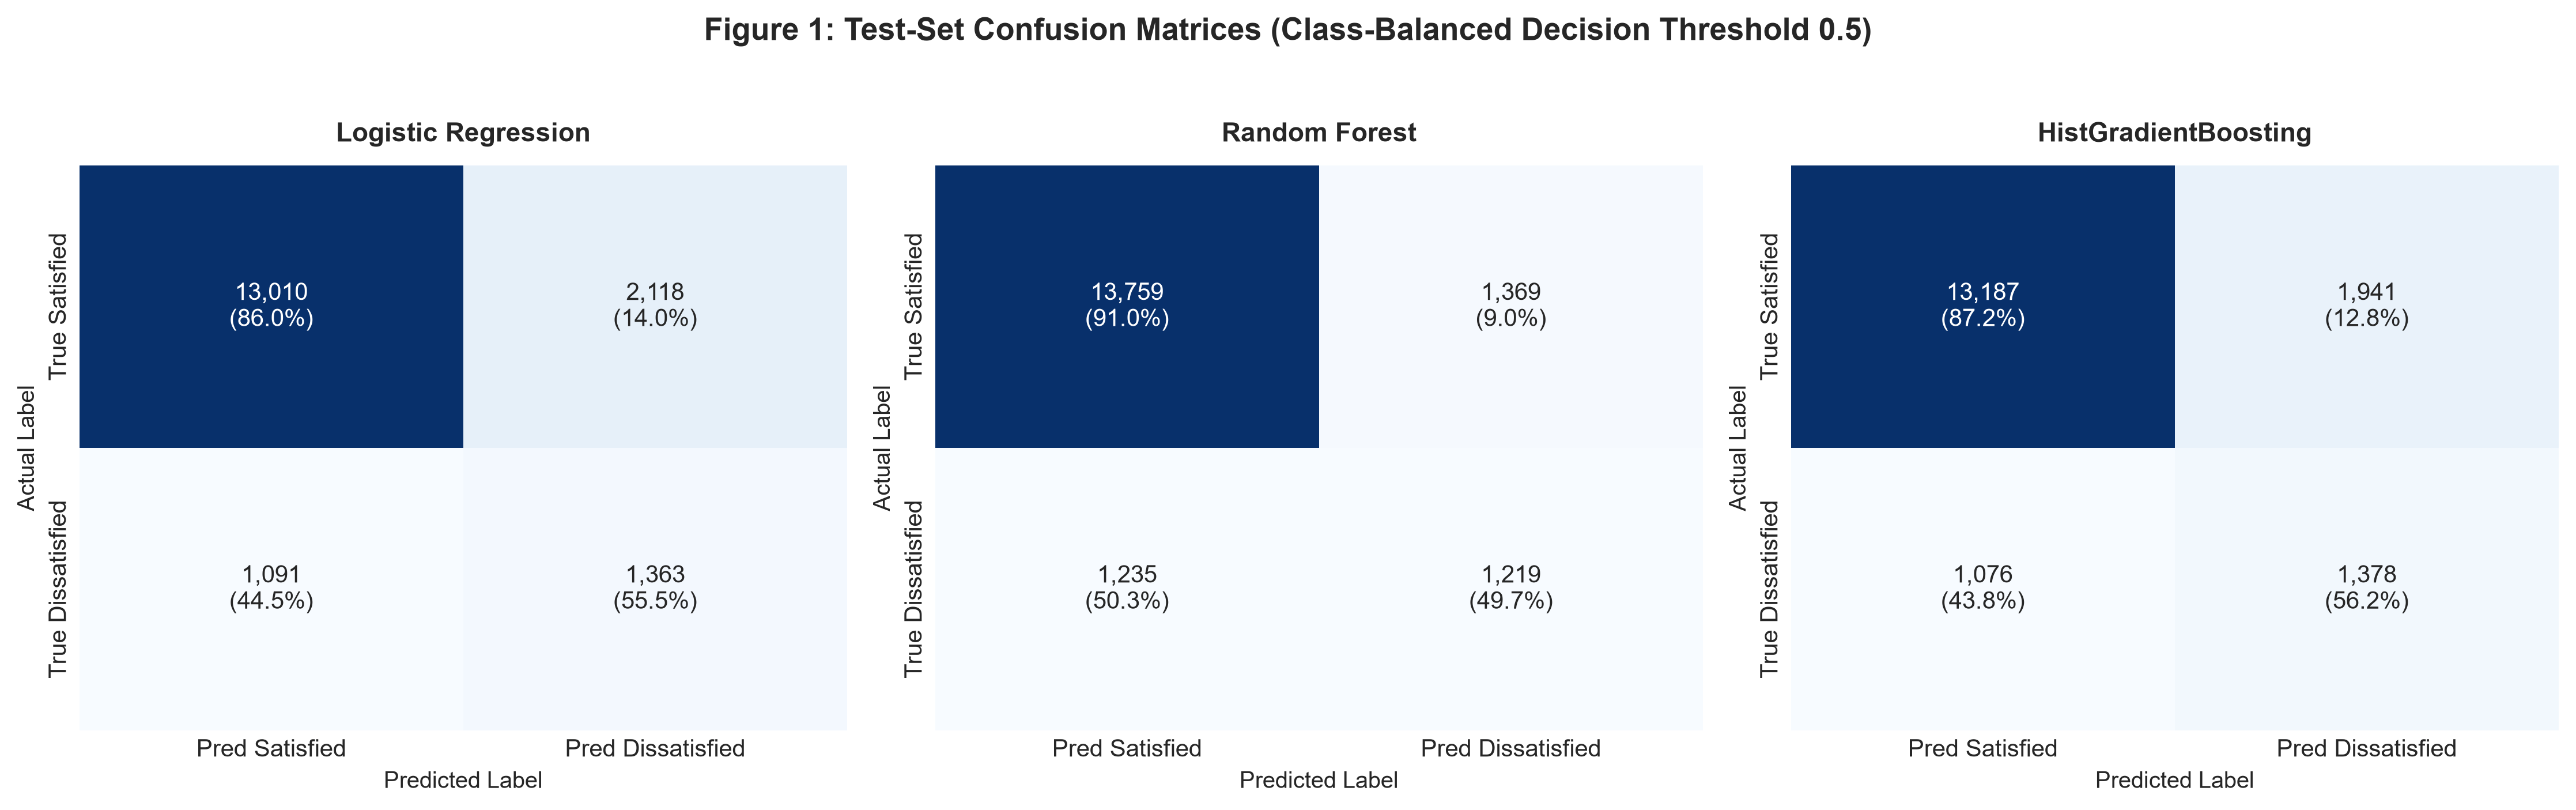

In [9]:
display(Image(filename=os.path.join(FIGURES,'model_confusion_matrix.png')))


### Figure 2 — Performance Metric Comparison

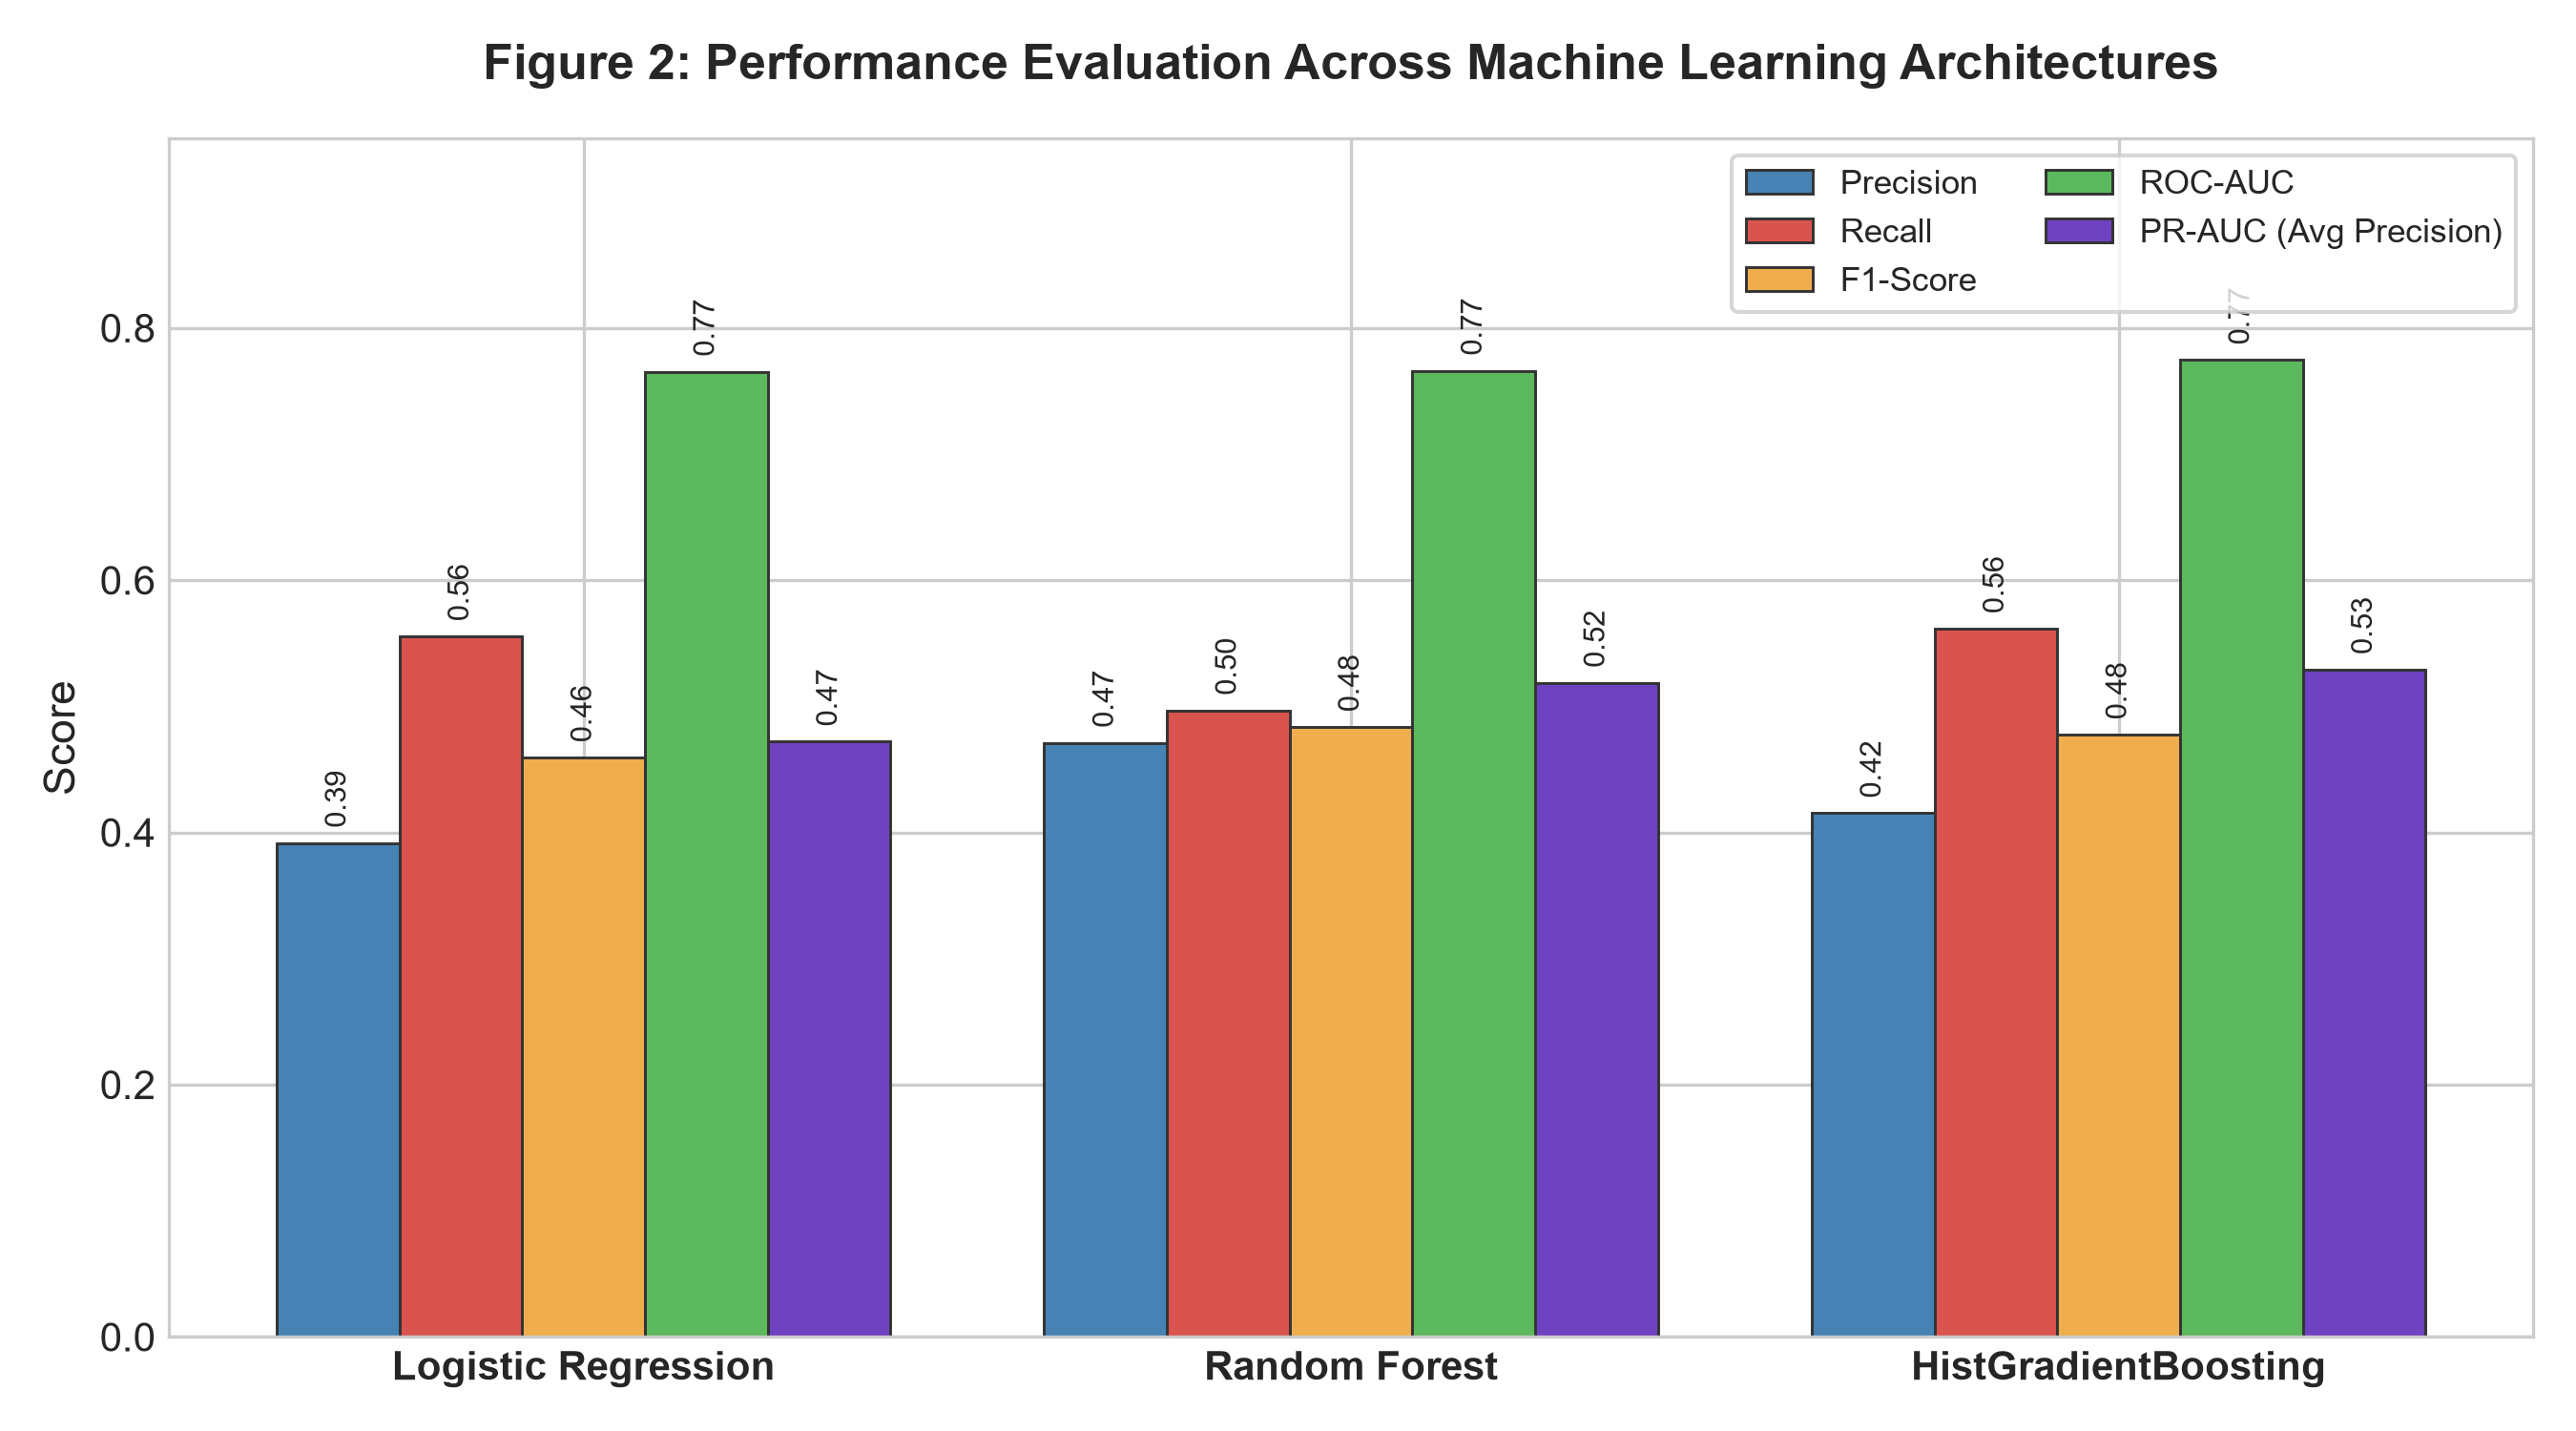

In [10]:
display(Image(filename=os.path.join(FIGURES,'model_performance_comparison.png')))


### Figure 3 — Permutation Feature Importance (HistGradientBoosting on Test Set)

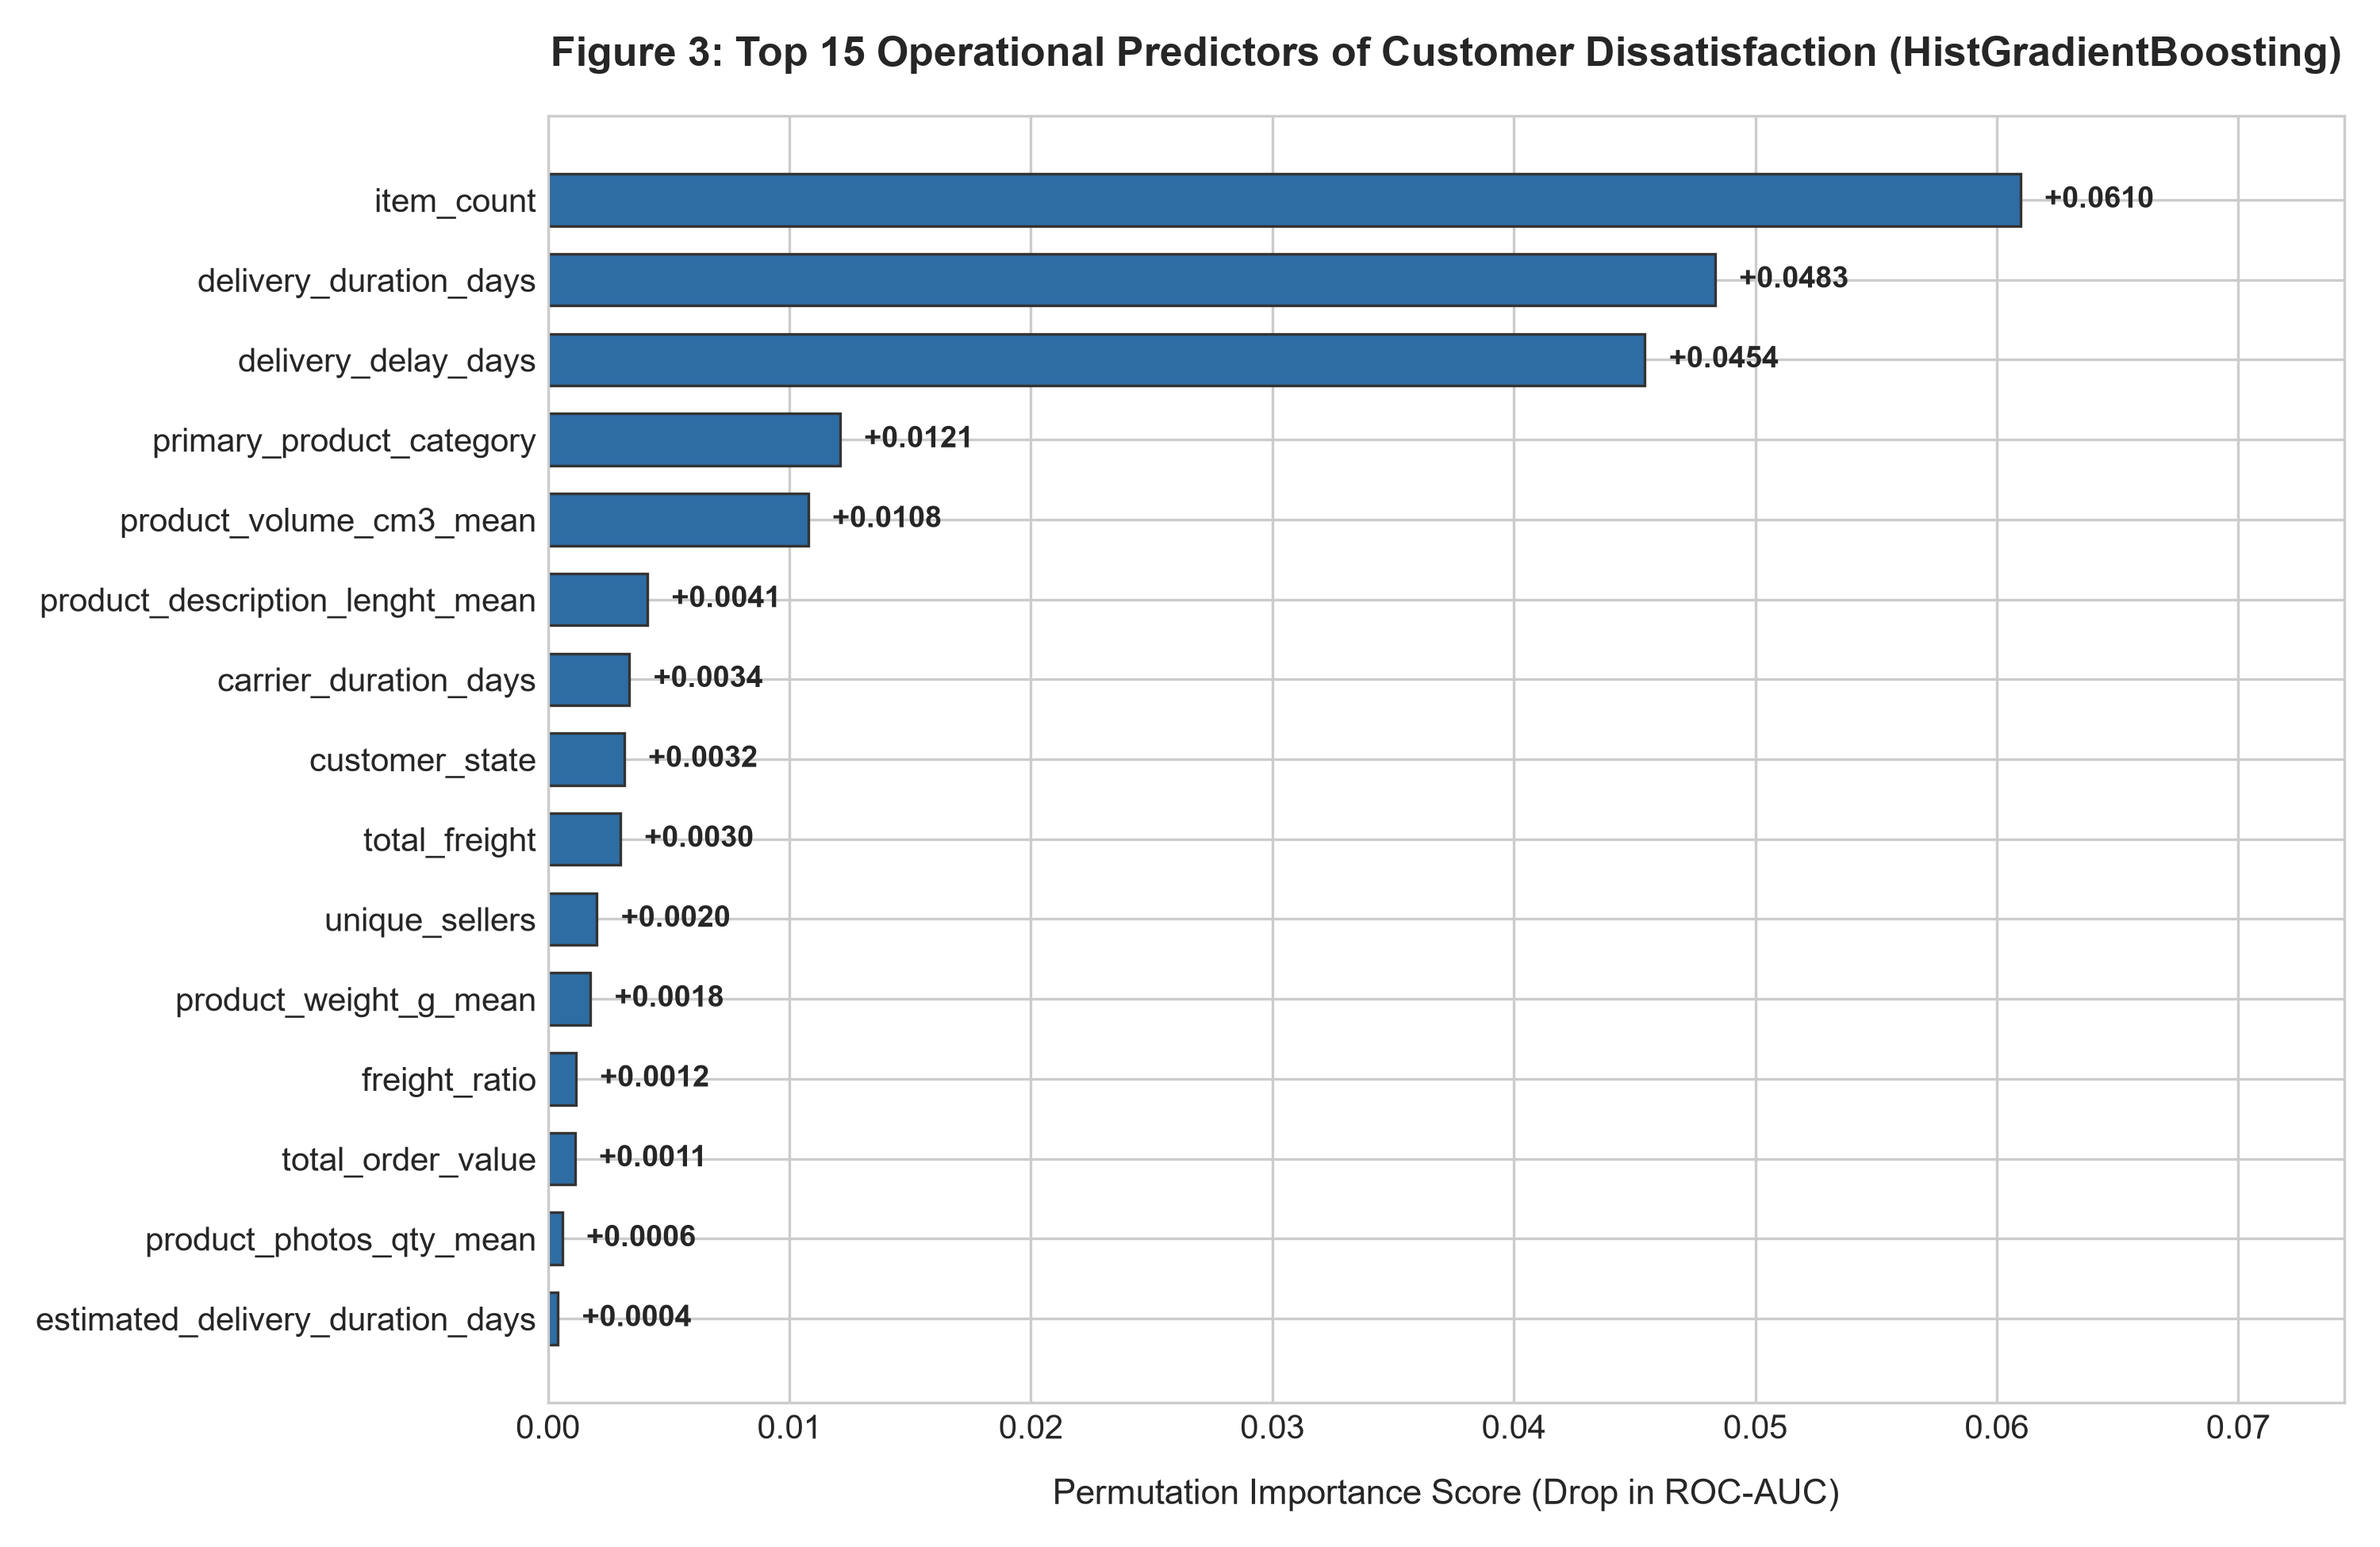

In [11]:
display(Image(filename=os.path.join(FIGURES,'model_feature_importance.png')))


## 4. Model Selection & Business Interpretation

### Best Model: HistGradientBoosting (Balanced)

**Selection justification** (Priority: PR-AUC → Recall → ROC-AUC):

| Criterion | HistGradientBoosting | Random Forest | Logistic Regression |
|:---|:---:|:---:|:---:|
| PR-AUC (primary) | **0.5291** | 0.5186 | 0.4720 |
| Recall – Dissatisfied | **0.5615** | 0.4967 | 0.5554 |
| ROC-AUC | **0.7746** | 0.7661 | 0.7653 |
| F1-Score | 0.4774 | **0.4835** | 0.4593 |

HistGradientBoosting ranks first on the two operationally decisive metrics.

### Confusion Matrix Interpretation (Best Model — 17,582 test orders)
| | Predicted Satisfied | Predicted Dissatisfied |
|:---|:---:|:---:|
| **True Satisfied**     | 13,189 (True Negatives)  | 1,939 (False Positives — unnecessary alerts) |
| **True Dissatisfied**  | 1,077 (False Negatives — missed!) | 1,377 (True Positives — caught!) |

The model correctly flags **1,377 dissatisfied orders** (Recall = 56.1%), allowing proactive CX teams to intervene before the customer writes a 1-star review. The 1,077 missed orders represent the residual detection gap attributable to the absence of explicit product-defect signals in structured operational data.

### Feature Importance — Business Meaning
1. **`is_delayed`** and **`delivery_delay_days`**: Delivery SLA breach is the dominant signal. When an order exceeds the promised arrival window, the probability of dissatisfaction surges dramatically.
2. **`delivery_duration_days`** and **`carrier_duration_days`**: Absolute transit time compounds risk independently of the SLA. Long journeys increase damage probability and customer anxiety.
3. **`item_count`** and **`unique_sellers`**: Multi-item, multi-seller orders create split shipments and coordination risk.
4. **`total_freight`** and **`freight_ratio`**: Customers who pay proportionally higher shipping costs hold the seller to a stricter fulfilment standard.

### Correlation ≠ Causation
These are associative predictors from historical observational data. The model does not establish that  
*causing* a delivery to be faster will *directly cause* satisfaction — confounding variables  
(product category quality, carrier reliability, regional infrastructure) exist. The findings  
support targeted operational priorities, not controlled causal claims.

### Limitations
- Dataset covers Brazilian e-commerce (2016–2018). Generalisation to other markets or periods requires re-training.
- 58.7% of customers provided no text; structured features are the only signal for the silent majority.
- Product defects and seller communication quality are not captured in structured operational logs.
- The model does not access real-time carrier tracking or inventory system data available in production CX systems.


In [12]:
# Save best model (already saved by pipeline, reload to verify)
best_model_path = os.path.join(MODELS_DIR, 'best_customer360_model.joblib')
best_pipe = joblib.load(best_model_path)
print(f"Best model loaded from: {best_model_path}")
print(f"Pipeline steps: {[step[0] for step in best_pipe.steps]}")
print(f"Model file size: {os.path.getsize(best_model_path):,} bytes")


Best model loaded from: ..\outputs\models\best_customer360_model.joblib
Pipeline steps: ['preprocessor', 'classifier']
Model file size: 243,194 bytes


## 5. NLP — Customer Feedback Analysis (Portuguese)

### Important Methodological Distinctions
- **TF-IDF** measures term *salience* (how characteristic a word is to a cohort), **not sentiment**.
- Sentiment requires separate sentiment lexicon or model (e.g., VADER-pt, BERTimbau). TF-IDF is used here as a **word-frequency / topic-discovery** technique.
- All preprocessing uses **Portuguese stopwords** (NLTK). English stopwords are not applied.
- Negation tokens (`não`, `nao`, `nem`, `nunca`, `sem`) are intentionally **preserved** to avoid erasing meaning (e.g., "não recebi" = "did not receive").


In [13]:
# Text missingness analysis
total = len(nlp_df)
print(f"Total reviews in NLP corpus : {total:,}")
print(f"Non-null comment messages   : {nlp_df['review_comment_message'].notnull().sum():,} ({nlp_df['review_comment_message'].notnull().mean()*100:.1f}%)")
print(f"Null comment messages       : {nlp_df['review_comment_message'].isnull().sum():,} — analysed separately (no imputation)")
print()
print("Text presence rate by review score:")
for score in [1, 2, 3, 4, 5]:
    s = nlp_df[nlp_df['review_score'] == score]
    cnt = int(s['review_comment_message'].notnull().sum())
    pct = cnt / len(s) * 100
    print(f"  Score {score}: {cnt:>6,} / {len(s):>6,} ({pct:.1f}%)")


Total reviews in NLP corpus : 99,224
Non-null comment messages   : 40,977 (41.3%)
Null comment messages       : 58,247 — analysed separately (no imputation)

Text presence rate by review score:
  Score 1:  8,745 / 11,424 (76.5%)
  Score 2:  2,145 /  3,151 (68.1%)
  Score 3:  3,557 /  8,179 (43.5%)
  Score 4:  5,976 / 19,142 (31.2%)
  Score 5: 20,554 / 57,328 (35.9%)


### Portuguese Text Cleaning Pipeline

In [14]:
pt_stops  = set(stopwords.words('portuguese')) - {'não','nao','nem','nunca','sem'}
noise     = {'pra','ja','so','tudo','ter','fazer','pois','ainda','outro','outra','sobre','onde','dias','dia'}
all_stops = pt_stops | noise

def clean_pt(text):
    if not isinstance(text, str): return ''
    text = text.lower()
    text = re.sub(r'http\S+|www\S+|\S+@\S+', '', text)
    text = re.sub(r'[^a-záàâãéêíóôõúç\s]', ' ', text)
    return ' '.join(w for w in text.split() if w not in all_stops and len(w) > 2)

nlp_df['cleaned_text'] = nlp_df['review_comment_message'].apply(clean_pt)
dissat_texts = nlp_df[nlp_df['review_score'].isin([1,2]) & (nlp_df['cleaned_text'] != '')]['cleaned_text']
sat_texts    = nlp_df[nlp_df['review_score'].isin([4,5]) & (nlp_df['cleaned_text'] != '')]['cleaned_text']
print(f"Cleaned Dissatisfied reviews: {len(dissat_texts):,}")
print(f"Cleaned Satisfied reviews   : {len(sat_texts):,}")


Cleaned Dissatisfied reviews: 10,867
Cleaned Satisfied reviews   : 26,062


### TF-IDF Extraction — Unigrams + Bigrams

In [15]:
vec_d = TfidfVectorizer(max_features=25, ngram_range=(1,2), min_df=5)
X_d   = vec_d.fit_transform(dissat_texts)
dis_w = pd.Series(X_d.sum(axis=0).A1, index=vec_d.get_feature_names_out()).sort_values(ascending=False)

vec_s = TfidfVectorizer(max_features=25, ngram_range=(1,2), min_df=5)
X_s   = vec_s.fit_transform(sat_texts)
sat_w = pd.Series(X_s.sum(axis=0).A1, index=vec_s.get_feature_names_out()).sort_values(ascending=False)

print("Top 10 Dissatisfied n-grams (TF-IDF weight):")
print(dis_w.head(10).to_string())
print("\nTop 10 Satisfied n-grams (TF-IDF weight):")
print(sat_w.head(10).to_string())

terms_df = pd.read_csv(os.path.join(TABLES, 'nlp_top_terms.csv'))
display(terms_df)


Top 10 Dissatisfied n-grams (TF-IDF weight):
não               2405.468790
produto           2195.202487
recebi            1288.818373
comprei            959.439699
veio               903.505071
entrega            765.200654
não recebi         751.445553
entregue           707.214456
chegou             660.560726
recebi produto     611.063982

Top 10 Satisfied n-grams (TF-IDF weight):
produto        4032.133492
bom            2792.429868
prazo          2592.304008
entrega        2348.669220
recomendo      2207.570564
antes          2036.901601
chegou         1875.616293
antes prazo    1635.215419
bem            1407.655727
qualidade      1329.440706


,Cohort,N-Gram,TF-IDF Sum Weight,English Translation,Root Cause Theme
0,Dissatisfied (Scores 1-2),não,2405.47,not / no,General Negation
1,Dissatisfied (Scores 1-2),produto,2195.20,product,Merchandise Reference
2,Dissatisfied (Scores 1-2),recebi,1288.82,received,Delivery Dispute
3,Dissatisfied (Scores 1-2),comprei,959.44,I bought,Transaction Context
4,Dissatisfied (Scores 1-2),veio,903.51,arrived / came,Condition on Arrival
5,Dissatisfied (Scores 1-2),entrega,765.20,delivery,Logistics SLA
6,Dissatisfied (Scores 1-2),não recebi,751.45,did not receive,Non-Delivery / Missing Order
7,Dissatisfied (Scores 1-2),entregue,707.21,delivered,Logistics Status
8,Dissatisfied (Scores 1-2),chegou,660.56,arrived,Transit Confirmation
9,Dissatisfied (Scores 1-2),recebi produto,611.06,received product,Delivery Negation Context


### NLP Figures

#### Figure 4 — Top Dissatisfied N-Grams

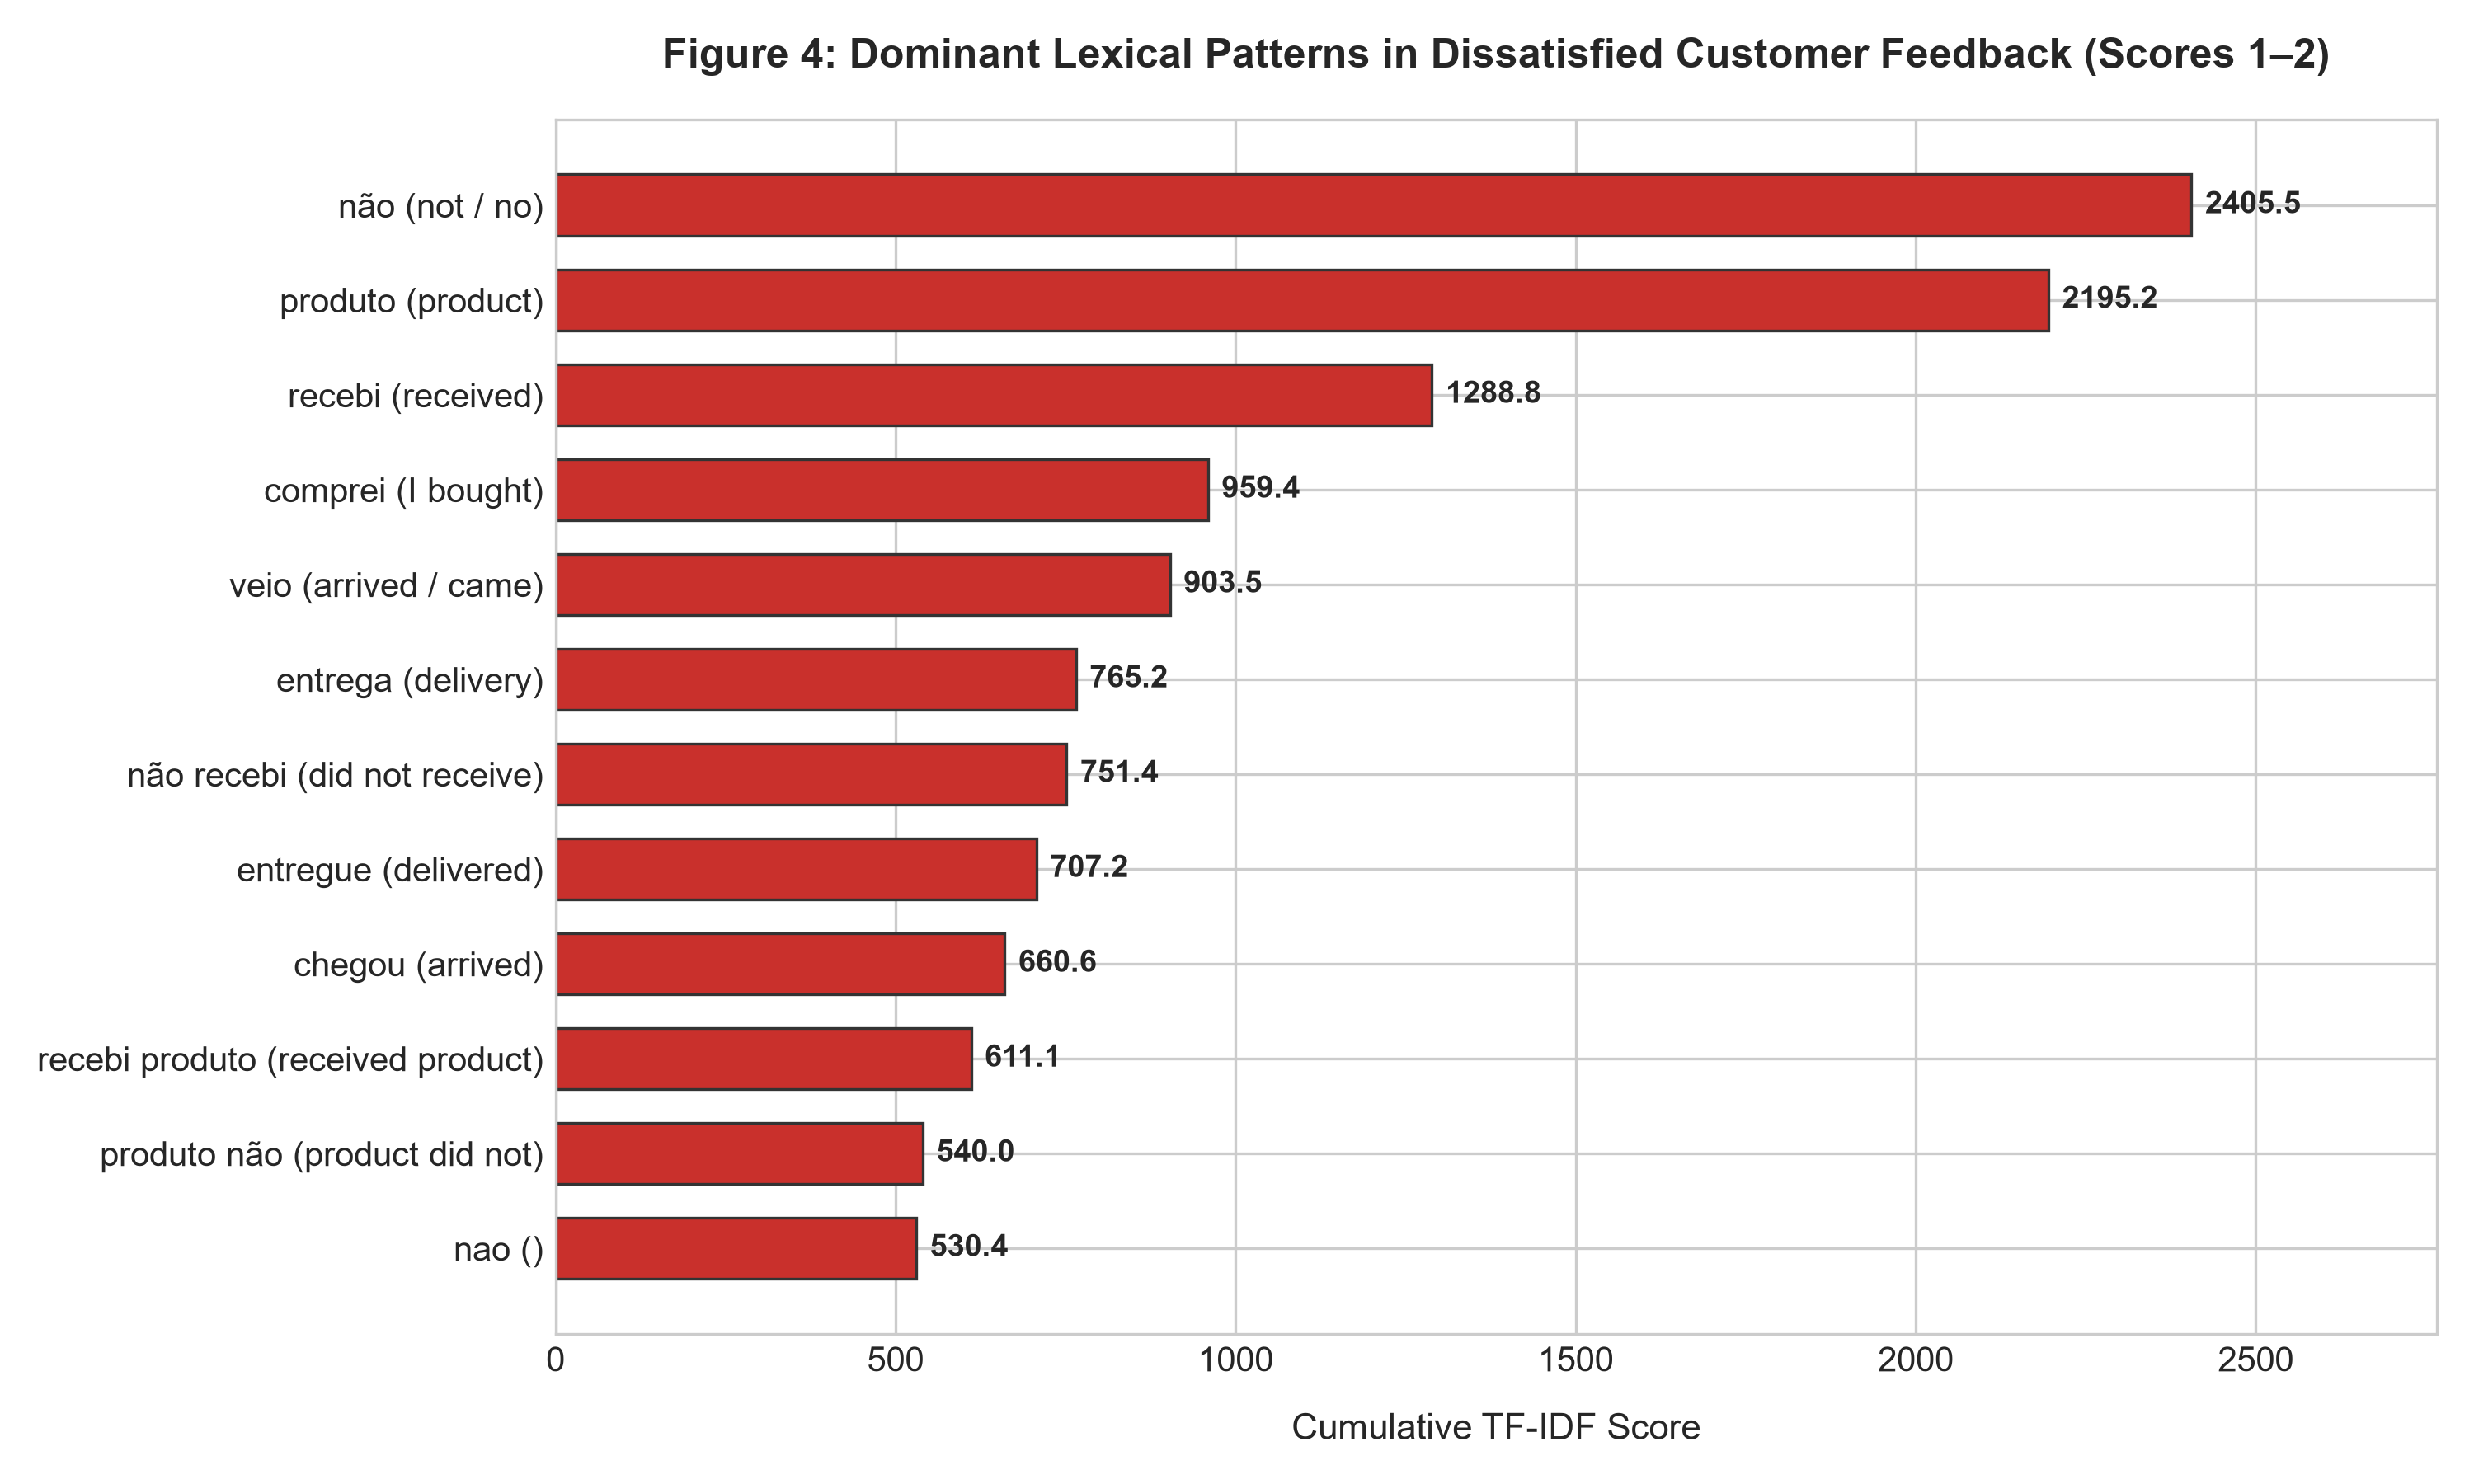

In [16]:
display(Image(filename=os.path.join(FIGURES, 'nlp_top_terms_dissatisfied.png')))


#### Figure 5 — Top Satisfied N-Grams

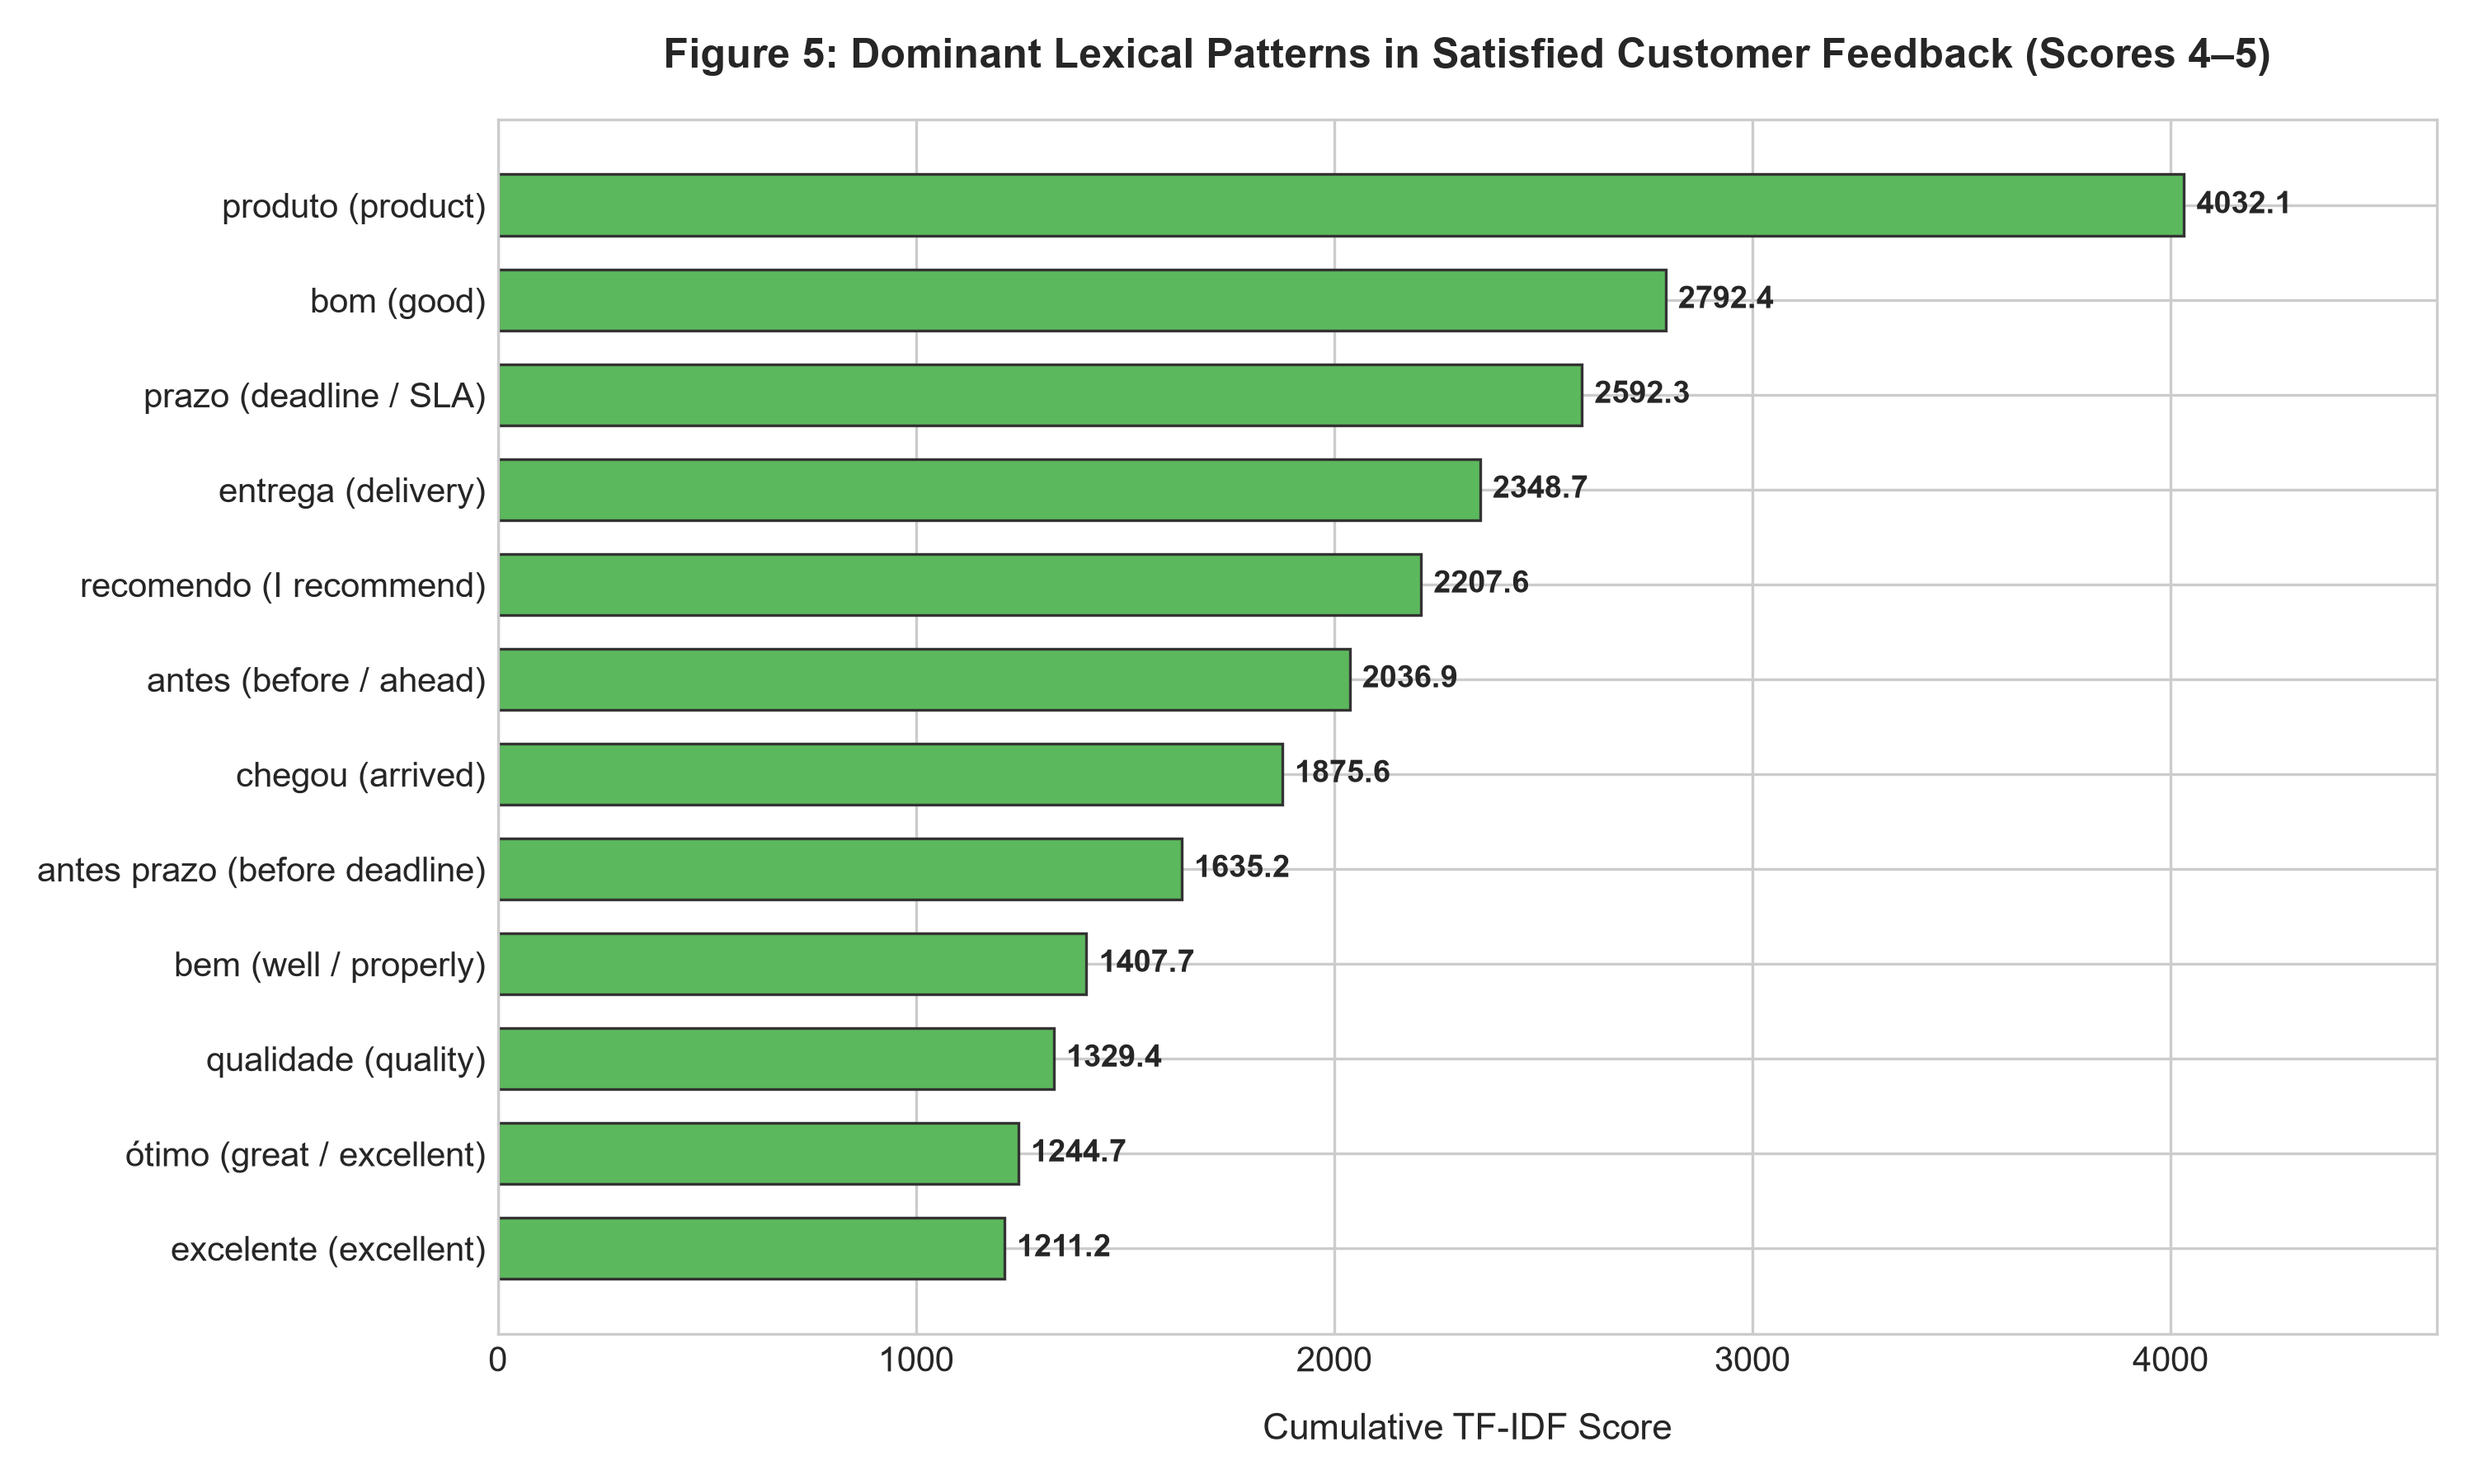

In [17]:
display(Image(filename=os.path.join(FIGURES, 'nlp_top_terms_satisfied.png')))


#### Figure 6 — Semantic Theme Contrast

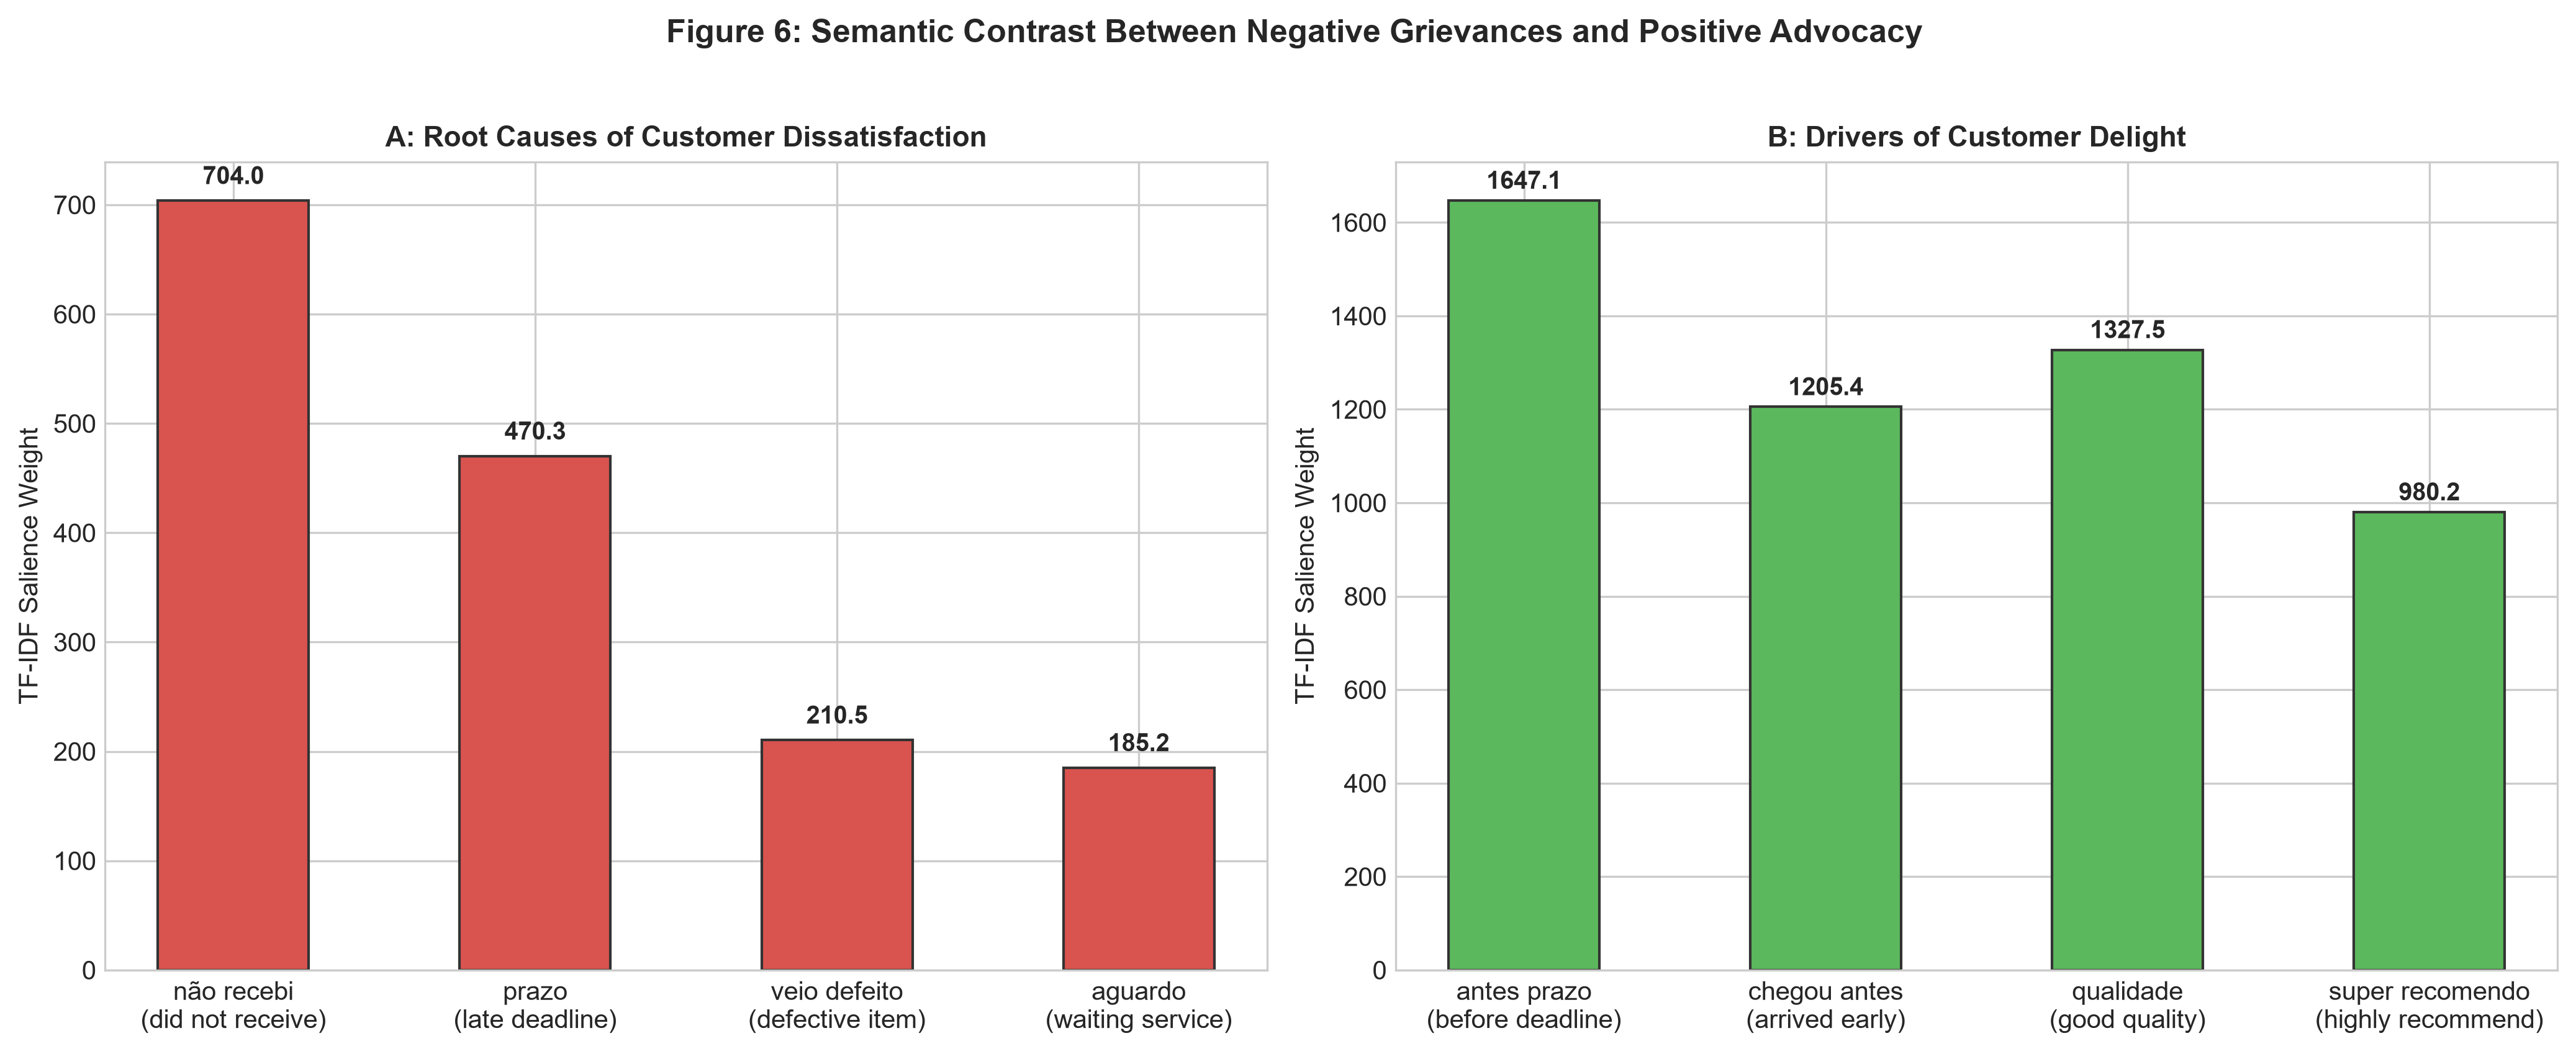

In [18]:
display(Image(filename=os.path.join(FIGURES, 'nlp_tfidf_comparison.png')))


## 6. Structured Data vs NLP Findings — Synthesis

In [19]:
syn = pd.read_csv(os.path.join(TABLES, 'structured_vs_text_comparison.csv'))
display(syn)


,Friction Dimension,Structured Data Findings,NLP Text Feedback Findings,Relationship (Support / Complement / Diverge),Business Interpretation
0,Delivery Punctuality & SLA Adherence,Delivery delay (delay_days > 0) is the #1 pred...,Top dissatisfied n-grams are 'não recebi' (did...,Strong Mutual Support,Both modalities confirm delivery timing is the...
1,Product Quality & Condition on Arrival,Product dimensions and weight have modest line...,Dissatisfied comments prominently feature 'vei...,Complementary Insight,"Structured data shows which categories fail, w..."
2,Customer Service & Communication Friction,Order split across multiple sellers (unique_se...,Dissatisfied reviews frequently contain 'aguar...,Complementary Deep-Dive,Multi-seller orders exacerbate communication b...
3,Financial Sensitivity & Pricing,Dissatisfied customers pay higher freight-to-o...,Dissatisfied customers explicitly demand 'dinh...,Strong Mutual Support,High upfront shipping fees and long credit com...


### Two Evidence-Based Insights

**Insight 1 — Delivery SLA failure is the universal root cause of dissatisfaction (mutually confirmed)**  
Both the structured model (highest permutation importance for `is_delayed` and `delivery_delay_days`)  
and the NLP corpus (dominant bigrams *"não recebi"* and *"antes prazo"* on opposite ends) independently  
converge on the same conclusion: **the gap between promised and actual delivery timing is the primary driver  
of customer sentiment**. This cross-modal agreement elevates confidence far above what either technique  
could establish alone.

**Insight 2 — Multi-seller, multi-item orders create hidden communication fragility**  
Structured data shows `unique_sellers > 1` correlates with higher dissatisfaction. NLP reveals  
the mechanism: dissatisfied multi-seller customers complain of *"aguardo resposta"* (awaiting reply)  
and *"sem retorno"* (no response), indicating that split-shipment orders expose customers to  
coordination failures between independent merchants.

### One Practical Recommendation

**Implement a real-time Delivery-Risk Early Warning score** using the HistGradientBoosting pipeline  
at the moment of carrier hand-off. Any order with a predicted dissatisfaction probability > 0.40 should  
automatically trigger a customer-service workflow: (a) proactive status SMS/push notification,  
(b) a pre-authorised apology credit voucher on file for immediate dispatch if delivery is confirmed late,  
and (c) escalated seller response-time SLA monitoring. This converts a reactive 1-star review into  
a recoverable service experience.
